# Irrigation Requirement Classification — EDA & Modeling

**Domain:** Agriculture | **Task:** Binary Classification | **Goal:** Predict whether irrigation is likely required from soil moisture, temperature, humidity, crop growth stage and recent rainfall.

This notebook walks through: data loading & quality checks, exploratory data analysis, preprocessing, model training & tuning (Logistic Regression, KNN, Decision Tree), evaluation, and interpretation.

> Dataset: see `../README.md` -> *Dataset* section for source/citation notes. This notebook reads `../data/irrigation_dataset.csv`.


In [2]:
import sys
sys.path.insert(0, "..")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.preprocessing import load_and_clean, split_X_y, VALID_RANGES

pd.set_option("display.max_columns", 20)
RAW_PATH = "../data/irrigation_dataset.csv"


## 1. Load raw data and inspect quality

In [ ]:
raw = pd.read_csv(RAW_PATH)
print(raw.shape)
raw.head()


### 1.1 Missing values

In [ ]:
raw.isna().mean().sort_values(ascending=False).to_frame("fraction_missing")


Missing values are present in `humidity_pct`, `soil_moisture_pct`, `rainfall_mm_last_7days`
and `crop_type` -- consistent with intermittent sensor dropout. We impute these
*inside* the modeling pipeline (median for numeric, most-frequent for categorical)
rather than before the train/test split, to avoid leaking test-set statistics
into training (data leakage).

### 1.2 Duplicate rows

In [ ]:
n_dupes = raw.duplicated().sum()
print(f"Exact duplicate rows: {n_dupes} ({n_dupes/len(raw):.1%})")


### 1.3 Outliers / physically impossible values

In [ ]:
for col, (lo, hi) in VALID_RANGES.items():
    if col in raw.columns:
        n_bad = ((raw[col] < lo) | (raw[col] > hi)).sum()
        print(f"{col}: {n_bad} values outside valid range [{lo}, {hi}]")


A handful of temperature readings above 50C and negative soil-moisture readings
are almost certainly sensor faults, not real observations. We clip these to the
valid physical range in `load_and_clean()` rather than dropping the rows, to
preserve sample size.

### 1.4 Clean the data using the shared pipeline function

In [ ]:
df = load_and_clean(RAW_PATH)
print(df.shape)
df.describe(include="all").T


## 2. Class balance

In [ ]:
df['irrigation_required'].value_counts(normalize=True)

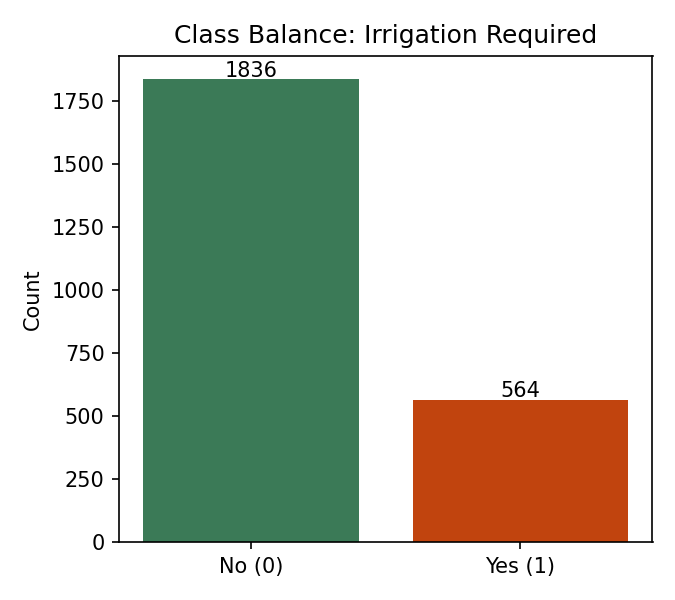

In [ ]:
from IPython.display import Image
Image("../reports/figures/class_balance.png")


The target is **imbalanced** (~23% positive / 'irrigation required' class).
This is realistic -- on most days a field does not need irrigation -- but it means
**accuracy alone is a misleading metric**; we prioritize F1-score and also report
ROC-AUC, precision and recall.

## 3. Feature distributions by class

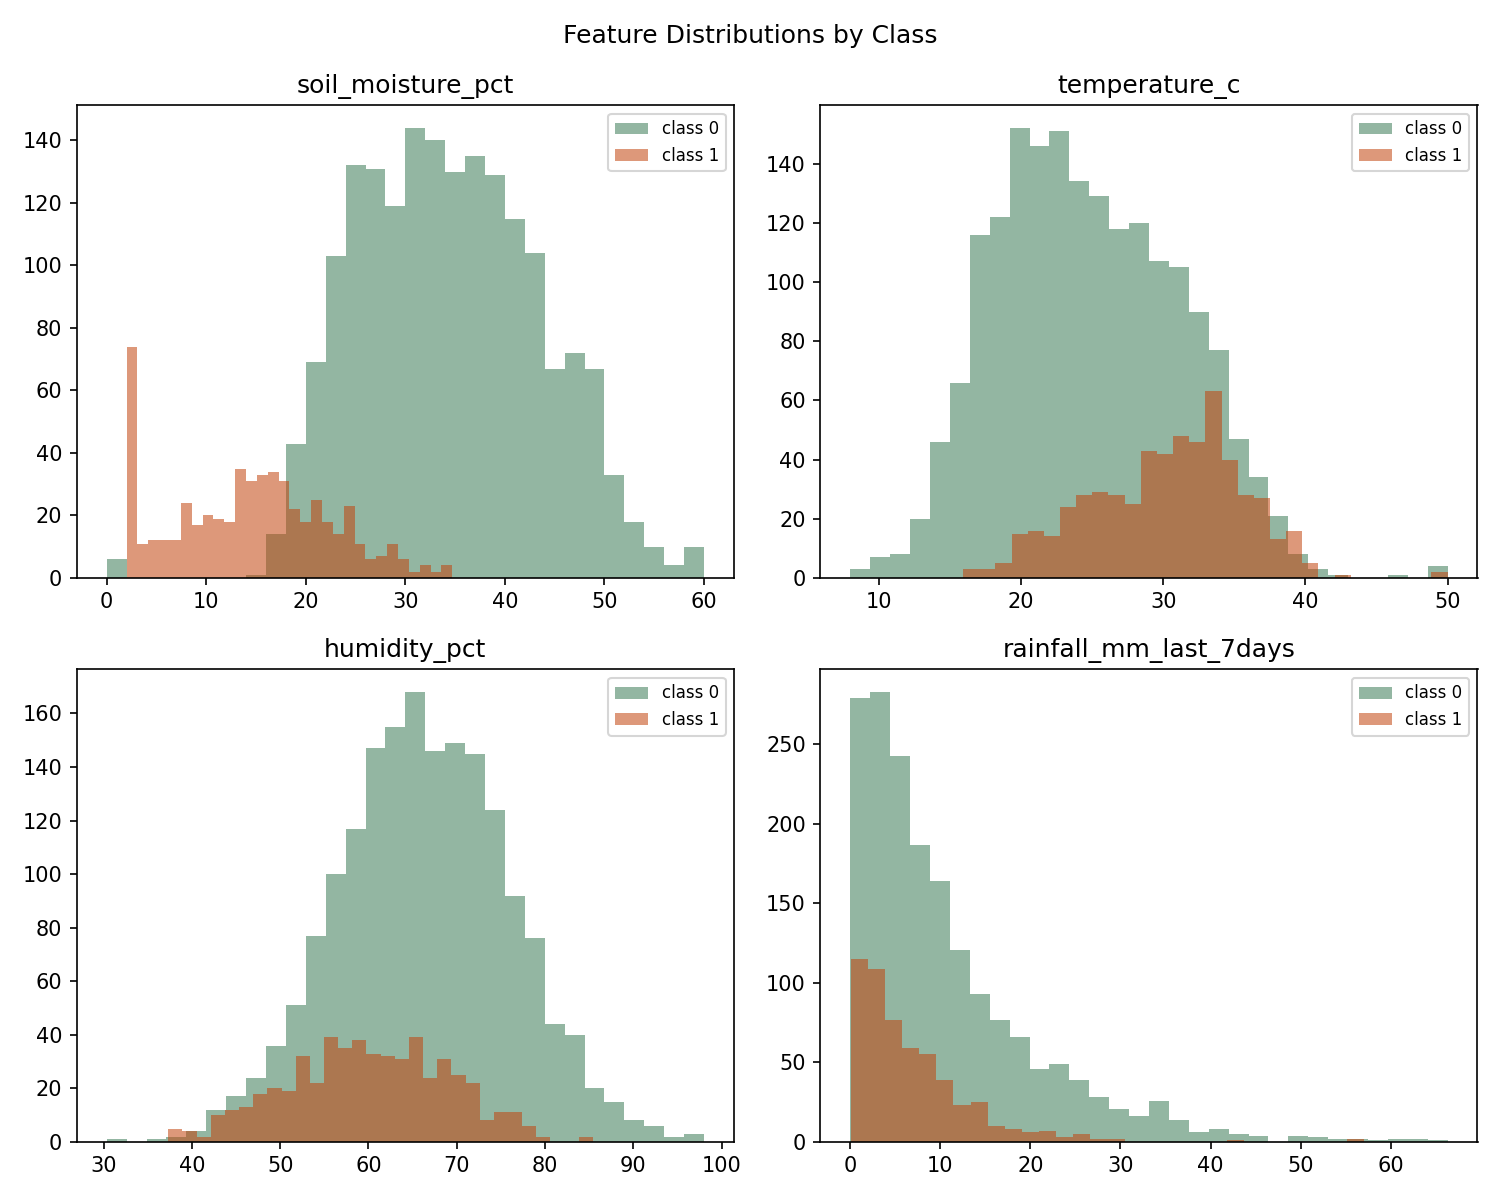

In [ ]:
Image("../reports/figures/feature_distributions.png")


Soil moisture shows the clearest separation between classes -- as expected,
since it's the most direct physical indicator of water stress. Temperature and
humidity separate less cleanly on their own, suggesting they mainly act as
*modifiers* of evapotranspiration rather than standalone predictors.

## 4. Correlation structure

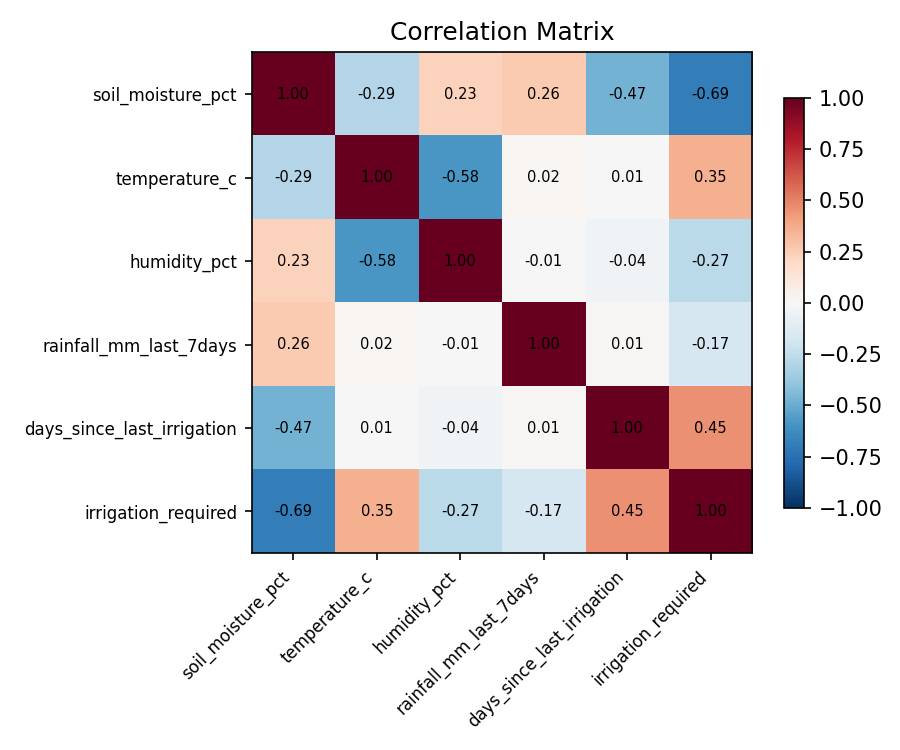

In [ ]:
Image("../reports/figures/correlation_heatmap.png")


`soil_moisture_pct` is negatively correlated with the target (lower moisture ->
more likely to need irrigation), while `days_since_last_irrigation` and
`temperature_c` are positively correlated. No pair of *input* features is
so strongly correlated that we'd worry about severe multicollinearity for
the linear model, though soil moisture and days-since-irrigation do move
together (both reflect the same underlying depletion process).

## 5. Categorical feature relationship: crop growth stage

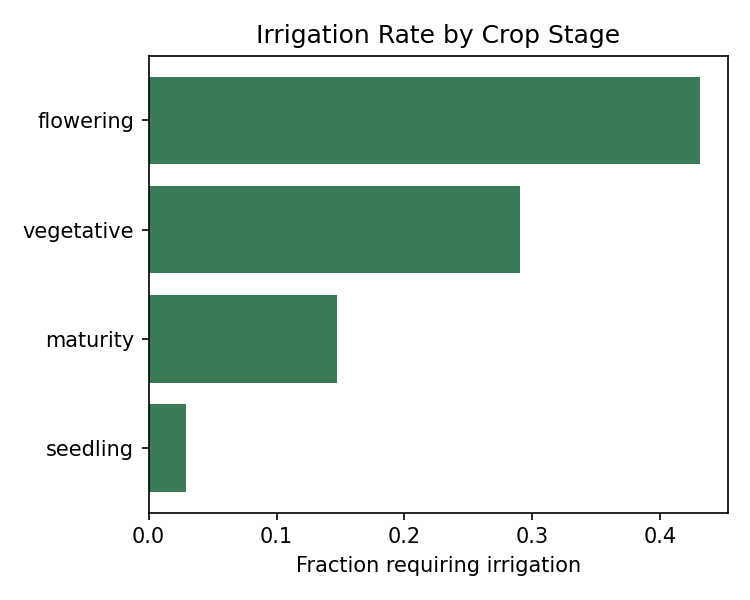

In [ ]:
Image("../reports/figures/irrigation_rate_by_stage.png")


Flowering-stage observations have the highest irrigation rate, consistent with
flowering having the highest crop water coefficient (Kc) among the four stages
modeled -- matching real agronomic practice.

## 6. Data leakage check

We confirm that the target `irrigation_required` was **not** derived from any
column we intend to still use as a feature at prediction time (e.g. it is not
a rescaled copy of `soil_moisture_pct`), and that `record_id` (a meaningless
row identifier) is dropped before modeling. Train/test split is stratified and
done *before* any imputation or scaling is fit, and all preprocessing lives
inside an sklearn `Pipeline` fit only on the training fold during
cross-validation -- this is the standard guard against leakage for this
project size.

## 7. Preprocessing, model training & tuning

See `src/train.py` for the full training script (identical logic, run as a standalone script so it can be reused by the Streamlit app). Summary of what it does:

1. Stratified 80/20 train/test split
2. `ColumnTransformer`: median imputation + standard scaling for numeric features, most-frequent imputation + one-hot encoding for categorical features
3. `GridSearchCV` (5-fold, scoring=F1) for each of: Logistic Regression, KNN, Decision Tree
4. Best model selected by held-out test F1 (tie-break: ROC-AUC)

In [ ]:
import json
with open("../models/metrics.json") as f:
    metrics = json.load(f)

summary = pd.DataFrame({
    name: {k: v for k, v in m.items() if k in ["accuracy", "precision", "recall", "f1", "roc_auc", "cv_f1_mean"]}
    for name, m in metrics.items()
}).T
summary.round(3)


## 8. Evaluation of the selected model

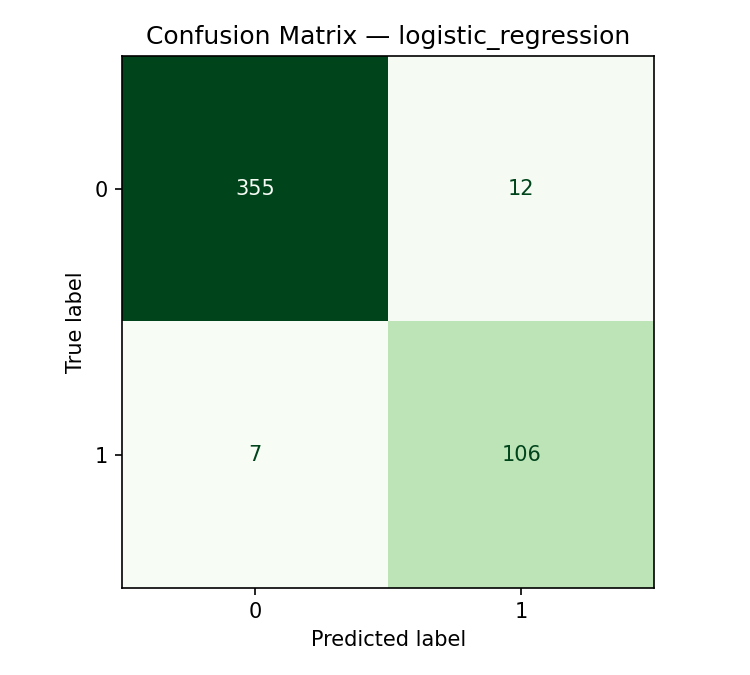

In [ ]:
with open("../models/model_name.txt") as f:
    best_name = f.read().strip()
print("Selected model:", best_name)
Image("../reports/figures/confusion_matrix.png")


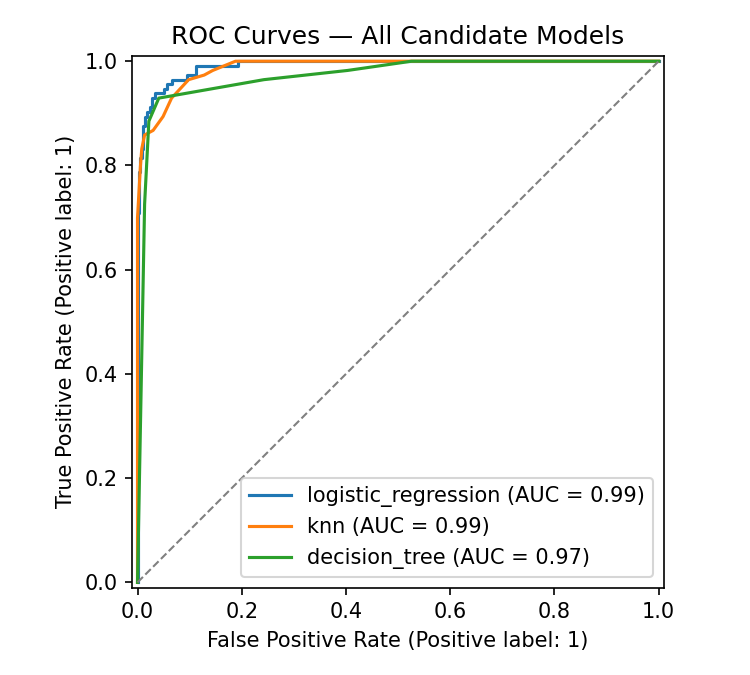

In [ ]:
Image("../reports/figures/roc_curves.png")


### Interpreting the metrics

- **Precision** (of predicted "irrigate" cases, how many truly needed it) matters for
  avoiding wasted water/labor from false alarms.
- **Recall** (of truly-needing-irrigation cases, how many we caught) matters more for
  avoiding crop stress from missed irrigation -- in most agricultural contexts a
  missed irrigation event is costlier than an unnecessary one, so recall is arguably
  the more business-critical metric here even though we optimized for F1 (a balance
  of both) as a reasonable default for an educational prototype.
- **ROC-AUC** > 0.95 for all three candidates indicates soil moisture and the
  engineered depletion signal are strong, fairly separable predictors in this
  dataset -- real sensor data would likely show more overlap/noise (see
  Limitations in the technical paper).

## 9. Error analysis

In [ ]:
from sklearn.model_selection import train_test_split
import joblib

X, y = split_X_y(df)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
model = joblib.load("../models/model.pkl")
y_pred = model.predict(X_test)

errors = X_test.copy()
errors["actual"] = y_test.values
errors["predicted"] = y_pred
errors = errors[errors["actual"] != errors["predicted"]]
print(f"{len(errors)} misclassified out of {len(X_test)} test samples ({len(errors)/len(X_test):.1%})")
errors.describe(include='all').T


Misclassified cases cluster near the decision boundary (soil moisture close to
the refill threshold), which is expected -- these are genuinely ambiguous
observations rather than a sign the model is missing an obvious pattern.

## 10. Model choice justification

**Logistic Regression** was selected as the final model:

- Highest held-out **F1-score** among the three candidates, with the top ROC-AUC.
- **Interpretable** coefficients (agronomists/farmers can sanity-check which
  factors push a prediction toward "irrigate"), which matters for a
  decision-support tool that should not be a black box.
- Cheap to run -- fits the "zero-cost / lightweight prototype" project constraint,
  and is trivial to embed in the Streamlit app.
- Decision Tree came close (and is even more interpretable via
  `feature_importance.png`) -- noted as a strong alternative in the technical paper.
- KNN was competitive but offers no interpretability and is slower at
  prediction time as the dataset grows (must scan training data each call).

## 11. Conclusion

See `reports/technical_paper.docx` for the full write-up (abstract, related work, methodology, results, discussion, limitations, future scope).